# 1. Theory: from PDEs to SDEs

**Notebook 1 of 3** · [2. Validation: FEM vs Monte Carlo](02_validation.ipynb) · [3. A real-world application](03_application.ipynb)

---

A boundary value problem is a *deterministic* object: find a function $u$ on a domain $D$ with a prescribed
behaviour in the interior and on the boundary. A diffusion process is a *random* object: a particle
that drifts and is shaken by noise. This notebook shows why they are the same thing.

> **The idea.** Release a random particle from $x\in D$ and let it move until it first touches $\partial D$.
> The value $u(x)$ of the PDE solution is the *average* of (what the particle collects on the way) + (what it receives when it hits the boundary).

What we will do:

1. State the Dirichlet–Poisson problem and attach a diffusion to its differential operator.
2. Show with **Itô's formula** why the operator $\mathcal{L}$ is the *drift of $f(X_t)$*.
3. Obtain the **Dynkin formula** and, from it, the stochastic representation $u(x)=\mathbb{E}^x[\cdots]$.
4. Understand the role of the **exit time** and of **regular boundary points**.
5. See it work in a 1-D case where everything has a closed form.
6. Turn the formula into an algorithm and list where its errors come from (this is what notebooks 2 and 3 measure).

## 1. The problem and the associated diffusion

We want to solve the **Dirichlet–Poisson problem**

$$
\begin{cases}
\mathcal{L} u(x) = -g(x), & x \in D \subset \mathbb{R}^n,\\[2pt]
u(x) = \phi(x), & x \in \partial D,
\end{cases}
$$

where $\mathcal{L}$ is a second-order operator

$$
\mathcal{L} = \sum_{i=1}^n b_i(x)\,\frac{\partial}{\partial x_i} + \sum_{i,j=1}^n a_{ij}(x)\,\frac{\partial^2}{\partial x_i\,\partial x_j},
\qquad a(x)=a(x)^{T}\ \text{positive (semi-)definite.}
$$

To $\mathcal{L}$ we associate the **Itô diffusion** $(X_t)_{t\ge 0}$ solving the SDE

$$
dX_t = b(X_t)\,dt + \sigma(X_t)\,dW_t,\qquad \tfrac12\,\sigma(x)\sigma(x)^{T} = a(x),
$$

with $W$ an $n$-dimensional Brownian motion. The factor $\tfrac12$ is not a convention to memorise: it is exactly what
makes the next computation work.

**Dictionary PDE ↔ SDE**

| PDE side | SDE side |
|---|---|
| first-order coefficient $b(x)$ (convection) | drift $b(X_t)\,dt$ |
| second-order coefficients $a(x)=\tfrac12\sigma\sigma^T$ (diffusion) | noise amplitude $\sigma(X_t)\,dW_t$ |
| source term $g$ | cost accumulated per unit of time along the path |
| boundary datum $\phi$ | payoff received where the path hits $\partial D$ |

In our running example (notebook 2): $a=I$, $b=(1,2)$, so $\sigma=\sqrt2\,I$, on $D=(-1,1)^2$.

## 2. Why $\mathcal{L}$? Itô's formula

Let $f\in C^2(\mathbb{R}^n)$. Itô's formula gives

$$
df(X_t)=\nabla f\cdot dX_t+\tfrac12\sum_{i,j}\partial_{ij}f\;d\langle X^i,X^j\rangle_t ,
\qquad d\langle X^i,X^j\rangle_t=(\sigma\sigma^T)_{ij}\,dt = 2a_{ij}\,dt .
$$

Substituting $dX_t=b\,dt+\sigma\,dW_t$:

$$
\boxed{\,df(X_t)=\underbrace{(\mathcal{L}f)(X_t)\,dt}_{\text{drift}}+\underbrace{\nabla f(X_t)^{T}\sigma(X_t)\,dW_t}_{\text{martingale increment}}\,}
$$

So $\mathcal{L}f$ is *the instantaneous drift of $f(X_t)$*, and this is where the factor $\tfrac12$ in $a=\tfrac12\sigma\sigma^T$ cancels.
Equivalently, $\mathcal{L}$ is the **generator** of $X$:

$$
\mathcal{L}f(x)=\lim_{t\downarrow0}\frac{\mathbb{E}^x[f(X_t)]-f(x)}{t}.
$$

Everything else follows from one observation: **if $\mathcal{L}u=-g$, the drift of $u(X_t)$ is known**, namely $-g(X_t)$.

## 3. The exit time

Let $D\subset\mathbb{R}^n$ be open. The **first exit time** from $D$ is

$$
\tau_D=\inf\{t\ge 0:\ X_t\notin D\},
$$

a stopping time of the natural filtration: at each time we can tell, from the past of the path, whether it has already left.
This is the random time at which the boundary condition is "read".

Two standing assumptions in the theory (and in the examples of this project):

* $\mathbb{E}^x[\tau_D]<\infty$. For a **bounded** domain and a **non-degenerate** diffusion (here $a=I$) this holds: wherever the particle is, with probability at least $p>0$ it leaves within one unit of time, so $\mathbb{P}^x(\tau_D>k)\le(1-p)^k$ decays geometrically (see Øksendal, Ch. 7).
* $\mathbb{E}^x\!\left[\int_0^{\tau_D}|g(X_s)|\,ds\right]<\infty$, automatic if $g$ is bounded.

## 4. Dynkin's formula and the stochastic representation

Integrate Itô's formula between $0$ and a stopping time $\tau$ with $\mathbb{E}^x[\tau]<\infty$:

$$
f(X_\tau)=f(x)+\int_0^\tau \mathcal{L}f(X_s)\,ds+\int_0^\tau \nabla f(X_s)^T\sigma(X_s)\,dW_s .
$$

The last term is a martingale with zero mean when the integrand is bounded, hence the **Dynkin formula**

$$
\boxed{\ \mathbb{E}^x[f(X_\tau)]=f(x)+\mathbb{E}^x\!\left[\int_0^\tau \mathcal{L}f(X_s)\,ds\right]\ }
$$

### Theorem (stochastic representation of the Dirichlet–Poisson problem)

Let $u\in C^2(D)\cap C(\overline D)$ be a bounded solution of $\mathcal{L}u=-g$ in $D$, $u=\phi$ on $\partial D$, and assume the two conditions of Section 3. Then for every $x\in D$

$$
\boxed{\ u(x)=\mathbb{E}^x\!\left[\phi(X_{\tau_D})\right]+\mathbb{E}^x\!\left[\int_0^{\tau_D} g(X_s)\,ds\right]\ }
$$

**Proof.** Take compact sets $D_k\uparrow D$ and let $\tau_k$ be the exit time from $D_k$, so $\mathbb{E}^x[\tau_k]<\infty$ and $u$ is $C^2$ near $\overline{D_k}$.
Dynkin with $f=u$ and $\tau=\tau_k$, using $\mathcal{L}u=-g$:

$$
u(x)=\mathbb{E}^x[u(X_{\tau_k})]+\mathbb{E}^x\!\left[\int_0^{\tau_k} g(X_s)\,ds\right].
$$

As $k\to\infty$, $\tau_k\uparrow\tau_D$ and, by path continuity, $X_{\tau_k}\to X_{\tau_D}\in\partial D$ where $u=\phi$. Since $u$ is bounded and continuous up to the boundary, dominated convergence in the first term and the integrability of $g$ in the second give the formula. $\blacksquare$

This is **the uniqueness half** of the story: *if* a classical solution exists, it must be this expectation. It is precisely what justifies comparing a finite-element solution with a Monte Carlo average: they approximate the same function.

### The converse (existence), and why the formula is natural

Define $w(x)$ as the right-hand side of the boxed formula. By the strong Markov property,

$$
w(X_{t\wedge\tau_D})+\int_0^{t\wedge\tau_D}g(X_s)\,ds=\mathbb{E}\!\left[\phi(X_{\tau_D})+\int_0^{\tau_D}g(X_s)\,ds\ \Big|\ \mathcal{F}_{t\wedge\tau_D}\right]
$$

is a **martingale**. A process $w(X_t)$ whose "drift" is $-g(X_t)$ is exactly what $\mathcal{L}w=-g$ says. This gives (Øksendal, Ch. 9):

1. $\lim_{t\uparrow\tau_D}w(X_t)=\phi(X_{\tau_D})$ almost surely: the boundary condition holds *along the paths*.
2. $\mathcal{A}w=-g$ in $D$, where $\mathcal{A}$ is the *characteristic operator* of $X$ (which coincides with $\mathcal{L}$ on $C^2$ functions).

If in addition the data are regular (e.g. $a$ uniformly elliptic with Hölder coefficients, $g$ Hölder, boundary satisfying an exterior cone/sphere condition), $w\in C^2(D)\cap C(\overline D)$ is a **classical** solution (Gilbarg–Trudinger, Ch. 6). That is our situation: $D=(-1,1)^2$, $a=I$, $b$ constant, $g$ smooth.

## 5. Reading the formula: special cases

$$
u(x)=\underbrace{\mathbb{E}^x[\phi(X_{\tau_D})]}_{\text{what is received on exit}}+\underbrace{\mathbb{E}^x\!\int_0^{\tau_D}g(X_s)\,ds}_{\text{what is accumulated on the way}}
$$

| $g$ | $\phi$ | $u(x)=\dots$ | Meaning |
|---|---|---|---|
| $0$ | $\mathbf 1_\Gamma$, $\ \Gamma\subset\partial D$ | $\mathbb{P}^x(X_{\tau_D}\in\Gamma)$ | probability of leaving through $\Gamma$ |
| $1$ | $0$ | $\mathbb{E}^x[\tau_D]$ | mean exit time |
| $0$ | general | $\mathbb{E}^x[\phi(X_{\tau_D})]$ | classical Dirichlet problem |
| general | $0$ | $\mathbb{E}^x\int_0^{\tau_D}g(X_s)\,ds$ | cost accumulated until exit |

Each row is a different *question about the same random particle*, and a different PDE. Notebook 3 uses the first two rows (and a smooth $\phi$) for a financial problem.

## 6. A 1-D example with closed-form answers

Take $\mathcal{L}=\tfrac12\frac{d^2}{dx^2}$ ($b=0$, $a=\tfrac12$, $\sigma=1$: standard Brownian motion) on $D=(-1,1)$.

* $g=1,\ \phi=0$: $\ \tfrac12u''=-1,\ u(\pm1)=0\ \Rightarrow\ u(x)=1-x^2=\mathbb{E}^x[\tau_D]$.
* $g=0,\ \phi(1)=1,\ \phi(-1)=0$: $\ u''=0\ \Rightarrow\ u(x)=\tfrac{1+x}{2}=\mathbb{P}^x(\text{exit at }+1)$ (the classical *gambler's ruin*).

We check both with the Monte Carlo solver of this project (`src/feynman_kac.py`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from src import plotstyle
from src.feynman_kac import feynman_kac_solver, Box

plotstyle.apply()

a, b = np.array([[0.5]]), np.array([0.0])        # L = (1/2) d^2/dx^2   (standard Brownian motion)
D = Box([-1.0], [1.0])
x_grid = np.linspace(-0.8, 0.8, 9)[:, None]

one  = lambda X: np.ones(len(X))
zero = lambda X: np.zeros(len(X))
exit_right = lambda X: (X[:, 0] > 0).astype(float)   # phi = 1 at x=+1, 0 at x=-1

tau_mc, tau_se = feynman_kac_solver(a, b, one,  zero,       x_grid, D, N=20000, dt=1e-3, seed=1, verbose=False)
p_mc,   p_se   = feynman_kac_solver(a, b, None, exit_right, x_grid, D, N=20000, dt=1e-3, seed=2, verbose=False)

xs = x_grid[:, 0]
print("   x     E[tau] MC (± se)    exact     |  P(exit +1) MC (± se)   exact")
for x, t, ts, p, ps in zip(xs, tau_mc, tau_se, p_mc, p_se):
    print(f"{x:+.1f}    {t:.4f} ± {ts:.4f}   {1 - x**2:.4f}    |   {p:.4f} ± {ps:.4f}       {(1 + x) / 2:.4f}")

   x     E[tau] MC (± se)    exact     |  P(exit +1) MC (± se)   exact
-0.8    0.3533 ± 0.0043   0.3600    |   0.0998 ± 0.0021       0.1000
-0.6    0.6447 ± 0.0053   0.6400    |   0.1995 ± 0.0028       0.2000
-0.4    0.8346 ± 0.0056   0.8400    |   0.3023 ± 0.0032       0.3000
-0.2    0.9644 ± 0.0058   0.9600    |   0.4014 ± 0.0035       0.4000
+0.0    1.0019 ± 0.0059   1.0000    |   0.5007 ± 0.0035       0.5000
+0.2    0.9580 ± 0.0058   0.9600    |   0.6009 ± 0.0035       0.6000
+0.4    0.8293 ± 0.0057   0.8400    |   0.6957 ± 0.0033       0.7000
+0.6    0.6403 ± 0.0053   0.6400    |   0.8003 ± 0.0028       0.8000
+0.8    0.3617 ± 0.0045   0.3600    |   0.9042 ± 0.0021       0.9000

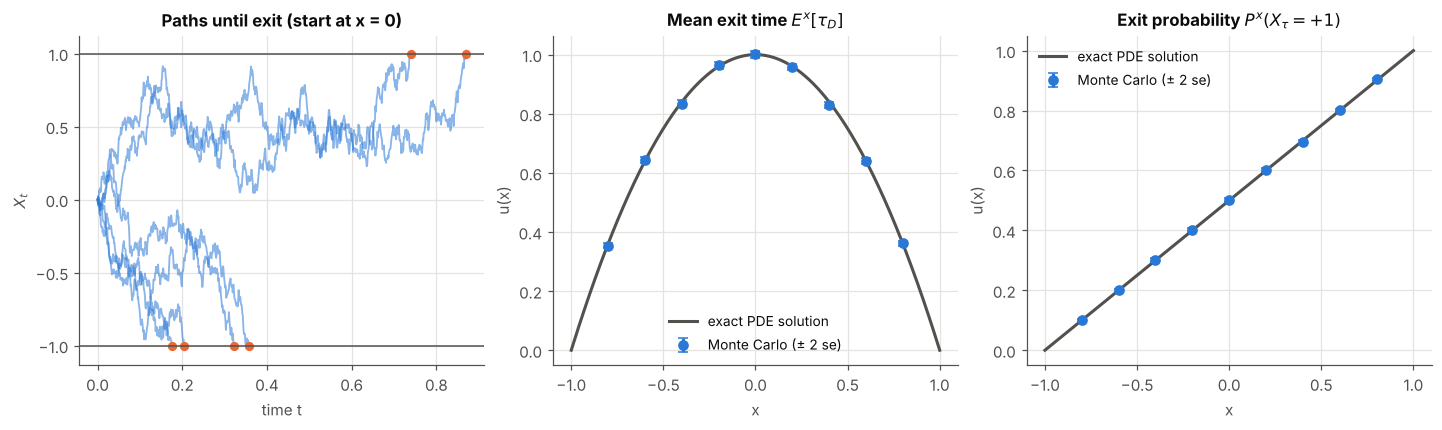

In [2]:
# A few sample paths of the diffusion until they leave D, from x = 0
rng = np.random.default_rng(7)
dt = 1e-3
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)

ax = axes[0]
for k in range(6):
    t, x, path = 0.0, 0.0, [0.0]
    while abs(x) < 1.0:
        x += np.sqrt(dt) * rng.standard_normal()
        t += dt
        path.append(x)
    ax.plot(np.arange(len(path)) * dt, path, color=plotstyle.BLUE, alpha=0.55, lw=1.2)
    ax.plot(t, np.sign(x), "o", color=plotstyle.ORANGE, ms=5)
ax.axhline(1, color=plotstyle.MUTED, lw=1); ax.axhline(-1, color=plotstyle.MUTED, lw=1)
ax.set(title="Paths until exit (start at x = 0)", xlabel="time t", ylabel="$X_t$")

xx = np.linspace(-1, 1, 200)
for ax, mc, se, exact, title, ylab in [
        (axes[1], tau_mc, tau_se, 1 - xx**2, r"Mean exit time $E^x[\tau_D]$", "u(x)"),
        (axes[2], p_mc,   p_se,   (1 + xx) / 2, r"Exit probability $P^x(X_\tau=+1)$", "u(x)")]:
    ax.plot(xx, exact, color=plotstyle.MUTED, lw=2, label="exact PDE solution")
    ax.errorbar(xs, mc, yerr=2 * se, fmt="o", color=plotstyle.BLUE, capsize=3, label="Monte Carlo (± 2 se)")
    ax.set(title=title, xlabel="x", ylabel=ylab)
    ax.legend(loc="best")
plt.show()

The orange dots are the exit points: the PDE solution at $x=0$ is the average, over many such paths, of what is collected along them.
Monte Carlo and the exact PDE solution agree within the statistical error. Note that there is **no mesh**: each point $x$ is computed independently.

## 7. Which boundary points can be reached? (regularity)

The theorem asks $u$ to be continuous up to $\partial D$. Whether the boundary condition is really attained depends on whether the particle starting *on* the boundary leaves *immediately*.

**Zero–one law (Blumenthal).** For $y\in\mathbb{R}^n$ the event $\{\tau_D=0\}$ belongs to the *germ* $\sigma$-algebra
$\mathcal{F}_{0+}=\bigcap_{t>0}\sigma(X_s:\,s\le t)$, so

$$
\mathbb{P}^y[\tau_D=0]\in\{0,1\}.
$$

Either almost every path leaves $D$ instantly or almost none does. No intermediate behaviour is possible.

**Definition.** A boundary point $y\in\partial D$ is **regular** if $\mathbb{P}^y[\tau_D=0]=1$ and **irregular** if it equals $0$.

* At regular points the Dirichlet condition $\lim_{x\to y}u(x)=\phi(y)$ **holds**. At irregular points the solution may fail to take the value $\phi(y)$.
* **Sufficient condition:** if $D$ satisfies an *exterior cone condition* at $y$ (a cone with vertex $y$ lies outside $D$ near $y$), then $y$ is regular for Brownian motion and for non-degenerate diffusions. This covers smooth and Lipschitz domains, **in particular our square, corners included**.
* **The exact criterion** is Wiener's test, which measures how "thick" the complement of $D$ is near $y$ (in terms of capacity).

**Examples of irregular points.** Irregular points need a very thin complement:

* $D=B(0,1)\setminus\{0\}\subset\mathbb{R}^2$: the puncture is irregular. Planar Brownian motion does not hit points, so a particle started at $0$ stays in $D$ for a positive time.
* **Lebesgue's spine** in $\mathbb{R}^3$: the tip of a sufficiently sharp thorn that enters $D$ from the outside is irregular.

In the plane, a boundary point lying on a connected piece of $\mathbb{R}^2\setminus D$ larger than a single point is always regular, so sharp corners and cusps there are *not* examples of irregularity.

## 8. Extensions (not used in the code, but part of the same theory)

* **Feynman–Kac with a potential.** For $\mathcal{L}u-c\,u=-g$ with $c\ge0$ the representation gains a discount factor:
  $u(x)=\mathbb{E}^x\!\left[e^{-\int_0^{\tau}c(X_s)ds}\phi(X_\tau)+\int_0^{\tau}e^{-\int_0^{s}c(X_r)dr}g(X_s)\,ds\right]$ (e.g. discounting in finance).
  What this project implements is the case $c=0$, sometimes called the Dynkin / Kakutani representation.
* **Parabolic problems** $\partial_t u=\mathcal{L}u$: the same argument with the time variable added to the state.
* **Other boundary conditions:** Neumann conditions correspond to *reflected* diffusions.
* **Walk on spheres.** For $\mathcal{L}=\tfrac12\Delta$ the mean-value property lets the particle jump to a random point on the largest sphere that fits in $D$, exiting in a few steps and with **no time-discretisation bias**.

## 9. From the formula to an algorithm

The representation suggests the **estimator**

$$
u(x)\;\approx\;\hat u_N(x)=\frac1N\sum_{k=1}^N\Big[\phi\big(X^{(k)}_{\tau}\big)+\sum_{m<\tau/\Delta t} g\big(X^{(k)}_{m\Delta t}\big)\,\Delta t\Big],
$$

where the paths $X^{(k)}$ are simulated with **Euler–Maruyama**: $X_{m+1}=X_m+b(X_m)\Delta t+\sigma(X_m)\sqrt{\Delta t}\,Z_m$, $Z_m\sim\mathcal{N}(0,I)$.

There are exactly **two sources of error**, and they behave very differently:

| Error | Origin | Size | How to reduce it |
|---|---|---|---|
| **Statistical** | finite $N$ | $O(N^{-1/2})$, estimated by the standard error $s/\sqrt N$ | more paths |
| **Discretisation bias** | the exit is only checked at the times $m\Delta t$: a path can leave and return between two steps, so $\tau$ is overestimated | $O(\sqrt{\Delta t})$ (Gobet 2000) | smaller $\Delta t$, **or** shift the boundary inward by $\approx0.5826\,\sigma_n\sqrt{\Delta t}$, which restores $O(\Delta t)$ (Broadie–Glasserman–Kou 1997, Gobet–Menozzi 2010) |

The standard error **does not see the bias**. A Monte Carlo result that looks "precise" can be systematically off. Notebook 2 shows that this is exactly what happens with the naive scheme, and measures both error rates.

**Why bother with Monte Carlo when finite elements exist?** FEM needs a mesh and its cost explodes with the dimension ($\sim h^{-n}$ unknowns), while Monte Carlo needs no mesh, works one point at a time, and its cost per point is essentially independent of $n$ (notebook 3).

---

### References

* B. Øksendal, *Stochastic Differential Equations*, Springer — Ch. 7 (diffusions), Ch. 8–9 (Dynkin, Dirichlet–Poisson problem).
* I. Karatzas, S. Shreve, *Brownian Motion and Stochastic Calculus*, Springer — Ch. 4.
* D. Gilbarg, N. Trudinger, *Elliptic PDEs of Second Order*, Springer — Ch. 6.
* E. Gobet, *Weak approximation of killed diffusion using Euler schemes*, Stoch. Proc. Appl. 87 (2000).
* M. Broadie, P. Glasserman, S. Kou, *A continuity correction for discrete barrier options*, Math. Finance 7 (1997).
* E. Gobet, S. Menozzi, *Stopped diffusion processes: boundary corrections and overshoot*, Stoch. Proc. Appl. 120 (2010).